In [45]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *
from pyproj import Transformer

In [46]:
'''
Precip_v1.xls
Excel file with a Precip sheet containing monthly precipitation sums by station and year, 
and a Info_prec sheet containing information about each record including start 
and end year and percentage complete. The format is the same as for Taver_v1.xls.'''

'\nPrecip_v1.xls\nExcel file with a Precip sheet containing monthly precipitation sums by station and year, \nand a Info_prec sheet containing information about each record including start \nand end year and percentage complete. The format is the same as for Taver_v1.xls.'

In [47]:
sourceData='/bettik/PROJECTS/pr-regional-climate/santolam/stations_central_asia/'
fileCentralAsia='Precip_v1_1.txt'

In [48]:
df_all_stations = pd.read_csv(sourceData+fileCentralAsia, sep="\t") 
#df_all_stations

In [49]:
station_check = df_all_stations.groupby('Code_WMO')['Name'].nunique()
#station_check

In [50]:
duplicates = station_check[station_check > 1]
print(duplicates)

Code_WMO
35796.0    2
36428.0    2
36665.0    2
36948.0    2
38396.0    2
38473.0    2
38507.0    2
38745.0    2
38838.0    2
38844.0    2
38880.0    2
38943.0    2
38954.0    2
Name: Name, dtype: int64


In [51]:
print(df_all_stations[df_all_stations['Code_WMO'] == 35796][['Code_WMO','Name', 'Long', 'Lat', 'Alt']].drop_duplicates()
)

      Code_WMO     Name   Long    Lat  Alt
385    35796.0  Balhash  75.00  46.90  398
449    35796.0  Balhash  75.08  46.80  398
1856   35796.0   Kuigan  74.20  45.38  345


In [52]:
###There are some WMO code with two different names, need to check is it is just a name change or an errror?
##For the moment I remove them

In [53]:
# First, ensure Code_WMO is numeric and drop NaNs for analysis
df_valid_codes = df_all_stations[df_all_stations['Code_WMO'].notna()].copy()

# Remove the duplicates (as before)
station_check = df_valid_codes.groupby('Code_WMO')['Name'].nunique()
duplicates = station_check[station_check > 1].index.tolist()

# Remove all rows with these duplicated WMO codes
df_clean = df_all_stations[~df_all_stations['Code_WMO'].isin(duplicates)].copy()

# Final check
print("Original rows:", len(df_all_stations))
print("Rows after removing duplicates:",len(df_clean))


Original rows: 16397
Rows after removing duplicates: 14585


In [54]:
## Model MAR
domain='GRp'
sourceDataGrid='/home/santolam/'
fileName_grF='NST.2014.01.01.00.GRi.nc'
#fileName_grM='NST.2000.01.01.00.GRa_Mera.nc_ICEmask'
dsF= xr.open_dataset(sourceDataGrid+fileName_grF) ## Year mean?
print('lon min',dsF.LON.values.min(),'lon max',dsF.LON.values.max())
print('lat min',dsF.LAT.values.min(),'lat max',dsF.LAT.values.max())

lon_min, lon_max =dsF.LON.values.min(),dsF.LON.values.max()
lat_min, lat_max= dsF.LAT.values.min(),dsF.LAT.values.max()
print(lon_min,lon_max)
print(lat_min,lat_max)

lon min 67.526566 lon max 77.156975
lat min 36.19467 lat max 41.38051
67.526566 77.156975
36.19467 41.38051


In [55]:
df_dom= df_clean[
    (df_clean['Long'] >= lon_min) & (df_clean['Long'] <= lon_max) &
    (df_clean['Lat'] >= lat_min) & (df_clean['Lat'] <= lat_max)
]

In [56]:
print(len(df_clean))
print(len(df_dom))


14585
5601


In [57]:
df_dom[0:5]

,Country,Code_WMO,Name,Long,Lat,Alt,Years,I,II,III,IV,V,VI,VII,VIII,IX,X,XI,XII
3650,213,36992.0,Aksai,72.83,40.05,3135,1952,1.5,7.9,10.8,33.2,44.5,31.6,44.8,25.3,33.9,0.9,2.7,2.8
3651,213,36992.0,Aksai,72.83,40.05,3135,1953,4.4,5.9,26.7,17.5,46.1,48.8,45.1,39.7,43.3,33.2,21.3,18.6
3652,213,36992.0,Aksai,72.83,40.05,3135,1954,7.2,3.4,5.3,28.2,24.2,45.6,58.6,85.4,15,2.0,2.7,3.9
3653,213,36992.0,Aksai,72.83,40.05,3135,1955,1.5,3,24.3,9.6,24.8,31,21.3,27.5,28.3,5.4,0.3,12
3654,213,36992.0,Aksai,72.83,40.05,3135,1956,3.6,17.2,16.3,28.1,21.1,66.9,3.5,22.0,17.4,5.2,1.1,3


In [58]:
# Replace -999.0 (missing value) with NaN
df = df_dom.replace(-999.0, pd.NA)

# List of month column names
month_cols = ['I', 'II', 'III', 'IV', 'V', 'VI', 'VII', 'VIII', 'IX', 'X', 'XI', 'XII']

df[month_cols] = df[month_cols].apply(pd.to_numeric, errors='coerce') #if not I have an error, they are strings
df.replace(-999.0, np.nan, inplace=True)


df['DJF'] = (df['XII'].shift(1) + df['I'] + df['II']) / 3 # DJF: Dec (from previous year), Jan, Feb
df['MAM'] = (df['III'] + df['IV'] + df['V']) / 3
df['JJA'] = (df['VI'] + df['VII'] + df['VIII']) / 3
df['SON'] = (df['IX'] + df['X'] + df['XI']) / 3
df['Annual'] = df[month_cols].mean(axis=1, skipna=True)

# Now include it in your seasonal_means DataFrame
seasonal_means = df[['Code_WMO', 'Name', 'Long', 'Lat', 'Alt', 'Years', 
                     'DJF', 'MAM', 'JJA', 'SON', 'Annual']]
#stations_list=[]
grouped = seasonal_means.groupby('Code_WMO')

stations_dict = {}
for wmo_code, group in grouped:
    group = group.reset_index(drop=True)
    #stations_list.append(group)  # for iteration
    stations_dict[wmo_code] = group.set_index('Years')  # for direct lookup and time series


In [59]:
print(len(seasonal_means))

5601


In [60]:
print(seasonal_means[0:5])

      Code_WMO    Name   Long    Lat   Alt  Years        DJF        MAM  \
3650   36992.0  Aksai   72.83  40.05  3135   1952        NaN  29.500000   
3651   36992.0  Aksai   72.83  40.05  3135   1953   4.366667  30.100000   
3652   36992.0  Aksai   72.83  40.05  3135   1954   9.733333  19.233333   
3653   36992.0  Aksai   72.83  40.05  3135   1955   2.800000  19.566667   
3654   36992.0  Aksai   72.83  40.05  3135   1956  10.933333  21.833333   

            JJA        SON     Annual  
3650  33.900000  12.500000  19.991667  
3651  44.533333  32.600000  29.216667  
3652  63.200000   6.566667  23.458333  
3653  26.600000  11.333333  15.750000  
3654  30.800000   7.900000  17.116667  


In [61]:
ann_clim = (
    seasonal_means
    .groupby(['Code_WMO', 'Name', 'Long', 'Lat', 'Alt'], as_index=False)
    .agg(
        iyear=('Years', 'min'),
        fyear=('Years', 'max'),
        ann_mean=('Annual', 'mean')
    )
)

In [62]:
ann_clim

,Code_WMO,Name,Long,Lat,Alt,iyear,fyear,ann_mean
0,36969.0,Atbashi,75.80,41.20,2025,1927,1995,24.326983
1,36992.0,Aksai,72.83,40.05,3135,1952,1998,22.594504
2,36994.0,Chatirkul,75.80,40.60,3540,1961,1990,20.405152
3,38447.0,Kaunchi,69.00,41.08,340,1927,1999,27.604412
4,38457.0,Tashkent,69.30,41.33,477,1877,2001,32.710333
...,...,...,...,...,...,...,...,...
71,38937.0,Shaartuz,68.13,37.28,380,1943,1990,12.973027
72,38947.0,Nizhniy Pyandge,68.58,37.20,329,1947,1990,14.787470
73,38951.0,Rushan,71.52,37.95,1966,1947,1990,21.171212
74,38956.0,Dzhavshangoz,72.46,37.36,3576,1935,1990,11.705035


In [63]:
#station_info['Long'].values

In [64]:

lat_stas =ann_clim['Lat'].values   #extract_column_float(data_dicts, 'Lat')
lon_stas = ann_clim['Long'].values 
elev_stas= ann_clim['Alt'].values 
codes =ann_clim['Code_WMO'].values

lon_MAR=dsF.LON;lat_MAR=dsF.LAT
iMAR_sta=[];jMAR_sta=[] ##coord of MAR pixel corresponding to station location

for pos in np.arange(len(lat_stas)):
    target_lon,target_lat=float(lon_stas[pos]),float(lat_stas[pos])
    # Compute distance to each grid point
    dist = np.sqrt((lon_MAR - target_lon)**2 + (lat_MAR - target_lat)**2)
    j, i = np.unravel_index(dist.argmin(), dist.shape) 
    jMAR_sta.append(j);iMAR_sta.append(i)

In [65]:
##Comparison of elevation (for example) at one point
SH_MAR_sta=dsF.SH[jMAR_sta[0],iMAR_sta[0]]
dif=elev_stas[0]-SH_MAR_sta.values
print(dif)

-627.819091796875


In [66]:

##For all points
SHList_dom=[];LONList_dom=[];LATList_dom=[]
for k in range(len(jMAR_sta)):
    tmp=dsF.SH[jMAR_sta[k],iMAR_sta[k]]
    SHList_dom.append(tmp)
    tmp1=dsF.LON[jMAR_sta[k],iMAR_sta[k]]
    LONList_dom.append(tmp1)
    tmp2=dsF.LAT[jMAR_sta[k],iMAR_sta[k]]
    LATList_dom.append(tmp2)


In [67]:
ds_stations_MARgrid= [{
    'codes_wmo':int(codes[i]),
    'lat_sta_ori': lat_stas[i],
    'lon_sta_ori':lon_stas[i],
    'elev_station_ori': elev_stas[i],
    'pix_i_sta_mar':iMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'pix_j_sta_mar':jMAR_sta[i], ## coord i,j: Position of station in the pixel of MAR grid (the closest)
    'elev_MAR_pix': SHList_dom[i].values,
    'lat_mar':LATList_dom[i].values, #Same as pix i,j to test that it it the same point
    'lon_mar':LONList_dom[i].values
} for i in range(len(SHList_dom))]


df_stations_MARgrid= pd.DataFrame(ds_stations_MARgrid)


In [68]:
print(len(df_stations_MARgrid['elev_MAR_pix']))

76


In [69]:
df_stations_MARgrid[0:5]

,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix,lat_mar,lon_mar
0,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36992,40.05,72.83,3135,63,60,3466.3733,40.057922,72.79341
2,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
3,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
4,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284


In [70]:
len(df_stations_MARgrid['elev_MAR_pix'])

76

In [71]:
##PRECIP comparison

In [72]:
domainM='GRp'; nx=ny=10
ds_RF_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRp/spin2/work/monthly/'+
    'RF_monsum_MARv3.14_ER5_spin2_GRp_*.nc')['RF']#.sel(ZTQLEV=2)
ds_RF= ds_RF_raw.rename({'TIME': 'time'})
ds_RF=ds_RF#[:,ny:-ny,nx:-nx]

ds_SF_raw=xr.open_mfdataset('/bettik/PROJECTS/pr-regional-climate/santolam/MARout_post/GRp/spin2/work/monthly/'+
    'SF_monsum_MARv3.14_ER5_spin2_GRp_*.nc')['SF']#.sel(ZTQLEV=2)
ds_SF= ds_SF_raw.rename({'TIME': 'time'})
ds_SF=ds_SF#[#:,ny:-ny,nx:-nx]

In [73]:
ds_TF=ds_RF+ds_SF
fyr=1990
ds_TF = ds_TF.sel(time=slice("1950-01-01", f"{fyr}-12-31"))

#vals,anoms=climb.seasonal_selection(ds_TF,'DJF',1980,2024)
vals,anoms=climb.seasonal_selection(ds_TF,'JFMAMJJASOND',1950,fyr)
#vals.time

In [74]:
df_stations_MARgrid[0:5]

,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix,lat_mar,lon_mar
0,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36992,40.05,72.83,3135,63,60,3466.3733,40.057922,72.79341
2,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
3,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
4,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284


In [75]:
print(dsF.SH.shape)

(82, 116)


In [76]:
ts_mar = vals.isel(Y=j, X=i)

In [77]:
mar_rows = []

for _, row in df_stations_MARgrid.iterrows():
    
    code = int(row.codes_wmo)
    i = int(row.pix_i_sta_mar)
    j = int(row.pix_j_sta_mar)

    # Extract MAR annual time series for this station
    #ts_mar = vals[:, j, i]  # time dimension already annual
    ts_mar = vals.isel(Y=j, X=i)
    mar_df = pd.DataFrame({
        'Code_WMO': code,
        'Years': ts_mar.time.values.astype(int),
        'MAR_Annual': ts_mar.values
    })

    mar_rows.append(mar_df)

df_mar_ann = pd.concat(mar_rows, ignore_index=True)

In [78]:
df_mar_ann

,Code_WMO,Years,MAR_Annual
0,36969,1950,1.070477
1,36969,1951,1.350200
2,36969,1952,0.900276
3,36969,1953,1.635111
4,36969,1954,1.137503
...,...,...,...
3111,38957,1986,15.478889
3112,38957,1987,15.001227
3113,38957,1988,8.187821
3114,38957,1989,6.061211


In [79]:
rows = []

for _, row in df_stations_MARgrid.iterrows():

    code = int(row.codes_wmo)

    # --- station obs (annual)
    sta = stations_dict[code]
    sta_years = sta.index.astype(int)
    sta_ann = sta['Annual']

    # --- MAR time series at station pixel
    ts_mar = vals[:, row.pix_j_sta_mar, row.pix_i_sta_mar]
    mar_years = ts_mar.time.values.astype(int)

    # --- common period
    iyear = max(sta_years.min(), mar_years.min())
    fyear = min(sta_years.max(), mar_years.max())

    if iyear > fyear:
        continue  # no overlap

    sta_c = sta_ann.loc[iyear:fyear]
    mar_c = ts_mar.sel(time=slice(iyear, fyear))

    # --- climatological means
    rows.append({
        'Code_WMO': code,
        'iyear': iyear,
        'fyear': fyear,
        'ann_mean_obs': sta_c.mean(),
        'ann_mean_MAR': mar_c.mean().item(),
        'bias_MAR-sta': mar_c.mean().item() - sta_c.mean(),
        'elev_sta': row.elev_station_ori,
        'elev_MAR_pix': row.elev_MAR_pix
    })

df_clim_MAR = pd.DataFrame(rows)


In [80]:
df_clim_MAR 

,Code_WMO,iyear,fyear,ann_mean_obs,ann_mean_MAR,bias_MAR-sta,elev_sta,elev_MAR_pix
0,36969,1950,1990,24.722154,1.547808,-23.174346,2025,2652.819
1,36992,1952,1990,22.485684,44.838775,22.353092,3135,3466.3733
2,36994,1961,1990,20.405152,16.712733,-3.692419,3540,3680.7898
3,38447,1950,1990,28.619206,0.571118,-28.048087,340,330.42392
4,38457,1950,1990,34.915244,0.000000,-34.915244,477,514.09454
...,...,...,...,...,...,...,...,...
71,38937,1950,1990,13.320089,0.003998,-13.316091,380,469.96008
72,38947,1950,1990,15.199196,0.194651,-15.004545,329,378.977
73,38951,1950,1990,21.010976,1.681948,-19.329027,1966,2630.3953
74,38956,1950,1990,11.711936,7.395488,-4.316449,3576,3842.2993


In [81]:
df = df_clim_MAR.merge(
    df_stations_MARgrid,
    left_on='Code_WMO',
    right_on='codes_wmo',
    how='inner'
)

df

,Code_WMO,iyear,fyear,ann_mean_obs,ann_mean_MAR,bias_MAR-sta,elev_sta,elev_MAR_pix_x,codes_wmo,lat_sta_ori,lon_sta_ori,elev_station_ori,pix_i_sta_mar,pix_j_sta_mar,elev_MAR_pix_y,lat_mar,lon_mar
0,36969,1950,1990,24.722154,1.547808,-23.174346,2025,2652.819,36969,41.20,75.80,2025,99,79,2652.819,41.20258,75.81277
1,36992,1952,1990,22.485684,44.838775,22.353092,3135,3466.3733,36992,40.05,72.83,3135,63,60,3466.3733,40.057922,72.79341
2,36994,1961,1990,20.405152,16.712733,-3.692419,3540,3680.7898,36994,40.60,75.80,3540,99,69,3680.7898,40.574116,75.78022
3,38447,1950,1990,28.619206,0.571118,-28.048087,340,330.42392,38447,41.08,69.00,340,17,77,330.42392,41.081726,68.96056
4,38457,1950,1990,34.915244,0.000000,-34.915244,477,514.09454,38457,41.33,69.30,477,21,81,514.09454,41.34211,69.28284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,38937,1950,1990,13.320089,0.003998,-13.316091,380,469.96008,38937,37.28,68.13,380,4,17,469.96008,37.27698,68.10759
72,38947,1950,1990,15.199196,0.194651,-15.004545,329,378.977,38947,37.20,68.58,329,10,16,378.977,37.230194,68.584595
73,38951,1950,1990,21.010976,1.681948,-19.329027,1966,2630.3953,38951,37.95,71.52,1966,47,27,2630.3953,37.978943,71.50143
74,38956,1950,1990,11.711936,7.395488,-4.316449,3576,3842.2993,38956,37.36,72.46,3576,59,17,3842.2993,37.35212,72.45836


In [82]:
# Derived variables
df['delta_z'] = df['elev_MAR_pix_x'] - df['elev_sta']
df['bias'] = df['bias_MAR-sta']
#df['bias_corr'] = df['bias_MAR-sta_corr']


In [83]:
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/
Saved: /home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/FIG9b_bias_PRE_stations_centralasia_rev1_Fanny1990.png


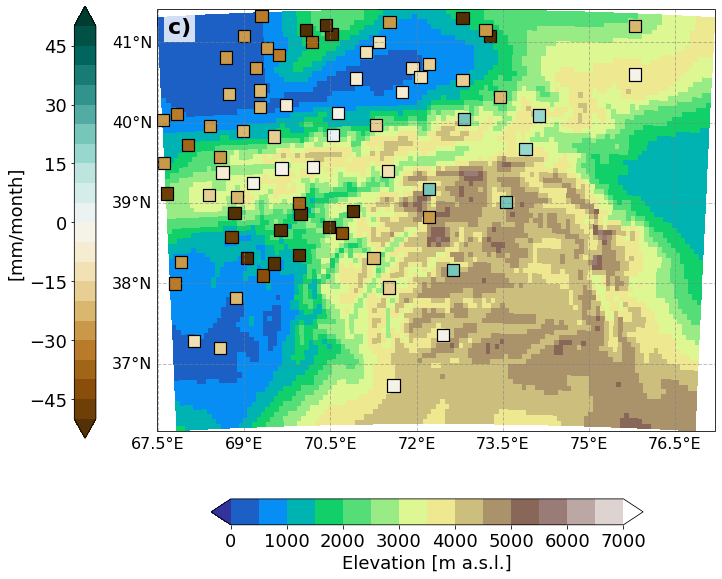

In [84]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

# =========================
# COLORMAP (BIAS)
# =========================
clevs = np.arange(-50, 55, 5)
cmap_bias = plt.get_cmap('BrBG')
norm_bias = mcolors.BoundaryNorm(clevs, cmap_bias.N, extend='both')

# =========================
# FIGURE
# =========================
fig = plt.figure(figsize=(10, 12))
ax = plt.axes(projection=ccrs.PlateCarree())

# =========================
# BACKGROUND: MAR elevation
# =========================
#m1 = ax.pcolormesh(
#    dsF.LON, dsF.LAT, dsF.SH,
#    cmap='Greys',
#    shading='auto',
##    transform=ccrs.PlateCarree()
#)

clevs_mod = np.arange(0, 7500, 500)
cmap_mod = plt.get_cmap('terrain')
norm = mcolors.BoundaryNorm(boundaries=clevs_mod, ncolors=cmap_mod.N, extend="both")

m1 = ax.pcolormesh(dsF.LON, dsF.LAT, dsF.SH, 
                       transform=ccrs.PlateCarree(),
                       cmap=cmap_mod, norm=norm, shading='auto')


# =========================
# STATIONS: BIAS
# =========================
sc = ax.scatter(
    df['lon_sta_ori'], df['lat_sta_ori'],
    c=df['bias'],                      # <-- aquí tu variable clave
    cmap=cmap_bias,
    norm=norm_bias,
    s=150, marker='s',
    edgecolors='black',
    linewidths=1.2,
    transform=ccrs.PlateCarree()
)

# =========================

gl = ax.gridlines(draw_labels=True, linewidth=1, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False
gl.right_labels = False
#gl.right_labels = Tr#
gl.xlabel_style = {"size": 16}
gl.ylabel_style = {"size": 16}
# =========================
# COLORBAR
# =========================
#cbar_ax = fig.add_axes([0.25, 0.16, 0.5, 0.03])  # [left, bottom, width, height]
#cbar = plt.colorbar(sc, cax=cbar_ax, orientation='horizontal', pad=0.08, shrink=0.8)
cbar_ax = fig.add_axes([0.01, 0.25, 0.03, 0.5])    # [left, bottom, width, height]
cbar = plt.colorbar(sc, cax=cbar_ax, orientation='vertical', pad=0.08, shrink=0.8)
cbar.ax.yaxis.set_label_position('left')
cbar.ax.yaxis.set_ticks_position('left')

cbar.set_label('[mm/month]', fontsize=18)
cbar.ax.tick_params(labelsize=18)

# --- Shared colorbar ---
#cbar_ax1 = fig.add_axes([0.25, 0.07, 0.5, 0.03])  # [left, bottom, width, height]
cbar_ax1 = fig.add_axes([0.2, 0.15, 0.6, 0.03])
cbar1 = fig.colorbar(m1, cax=cbar_ax1, orientation="horizontal")
cbar1.set_label("Elevation [m a.s.l.]", fontsize=18)
cbar1.ax.tick_params(labelsize=18)
# =========================
# PANEL LABEL
# =========================
ax.text(
    0.02, 0.98, 'c)',
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
)

# =========================
# OPTIONAL (MUY RECOMENDADO)
# =========================
#ax.set_title('MAR Temperature Bias (°C)', fontsize=16)
ax.set_aspect(1.4)
# =========================
# SAVE / SHOW
# =========================
#plt.tight_layout()
print(plotsDir)
plotname='FIG9b_bias_PRE_stations_centralasia_rev1_Fanny1990'
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")
plt.show()

In [85]:
fz=18

Saved: /home/santolam/RECAP/figures/paper_on_validation_RECAP/FIG9c_scatter_central_asia_pre.GRp_SH_ICE_pamir_rev1_Fanny1990.png


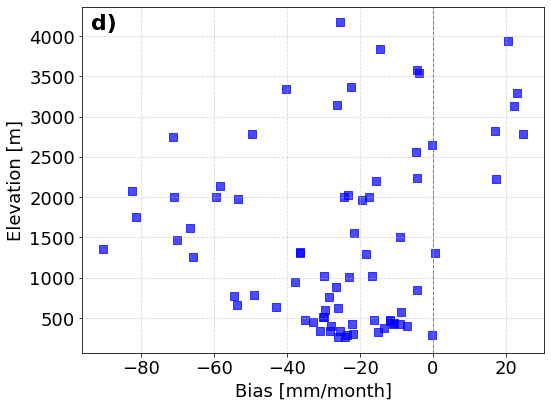

In [86]:
import matplotlib.pyplot as plt

# Compute the overlapping period
df_clim_MAR['period'] = df_clim_MAR['fyear'] - df_clim_MAR['iyear'] + 1

# Define a function to choose marker based on period
#def get_marker(period):
#    if period  < 5:
#        return 's'  # square
#    elif 5 <= period < 10:
#        return 'o'  # circle
#    elif 10 <= period < 20:
#        return 'X'  # circle
#    else:
#        return 'D'  # diamond for >10 years

plt.figure(figsize=(8,6))

# Loop through each row and plot with appropriate marker
for _, row in df_clim_MAR.iterrows():
    plt.scatter(row['bias_MAR-sta'], row['elev_sta'], marker='s',
                color='blue', alpha=0.7, s=80)

plt.axvline(0, color='grey', linestyle='--', linewidth=1)
#plt.xlabel('Bias MAR - Station (Annual Mean)')
plt.xlabel('Bias [mm/month]',fontsize=fz)
plt.ylabel('Elevation [m]',fontsize=fz)
#plt.title('Bias vs Station Elevation (Marker: overlapping period)')
plt.grid(True, linestyle='--', alpha=0.5)

# Optional legend
#from matplotlib.lines import Line2D
#legend_elements = [
##    #Line2D([0], [0], marker='^', color='w', label='<1 year', markerfacecolor='blue', markersize=8),
#    Line2D([0], [0], marker='s', color='w', label='1-5 years', markerfacecolor='blue', markersize=8),
#    Line2D([0], [0], marker='o', color='w', label='5-10 years', markerfacecolor='blue', markersize=8),
#    Line2D([0], [0], marker='D', color='w', label='10-20 years', markerfacecolor='blue', markersize=8),
#    Line2D([0], [0], marker='X', color='w', label='>20 years', markerfacecolor='blue', markersize=8)
#]
ax = plt.gca()

ax.text(
    0.02, 0.98,            # position relative à l'axe
    'd)',
    transform=ax.transAxes,
    fontsize=22,
    fontweight='bold',
    va='top',
    ha='left',
    bbox=dict(facecolor='white', edgecolor='none', alpha=0.9, pad=2)
)

plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "figure.titlesize": 18,
})
plotsDir = "/home/santolam/RECAP/figures/paper_on_validation_RECAP/"
plotname = f"FIG9c_scatter_central_asia_pre.{domain}_SH_ICE_pamir_rev1_Fanny1990"
plt.tight_layout()
plt.savefig(f"{plotsDir}{plotname}.png", bbox_inches="tight", dpi=300)
print(f"Saved: {plotsDir}{plotname}.png")

plt.show()


In [87]:
#ds_TF